# Likelihood-Based Signal Extraction, Hypothesis Testing, and Likelihood Geometry in CMS $Z \to \mu^+\mu^-$
**Author:** Aditya Kumar Choubey  
**Course:** Statistical Inference for High Energy Physics  
**Dataset:** CERN Open Data — 2016 CMS DoubleMuon Primary Dataset (Run 2016G, $\sqrt{s} = 13\text{ TeV}$, NanoAODv9, Record [30522](https://opendata.cern.ch/record/30522))  
**Analysis Framework:** Remote Streaming via `uproot`, Likelihood Optimization via `iminuit`, Statistical Inference via `scipy.stats`

---

## 1. Physics Motivation & Problem Statement

The $Z$ boson ($m_Z \approx 91.1876\text{ GeV}$, $\Gamma_Z \approx 2.4952\text{ GeV}$) is the neutral electroweak gauge mediator of the Standard Model and serves as the primary "standard candle" for detector calibration, momentum scale alignment, and luminosity determination at the LHC. The dimuon decay channel,
$$p + p \longrightarrow Z / \gamma^* + X \longrightarrow \mu^+ \mu^- + X,$$
offers an exceptionally clean experimental signature characterized by high trigger efficiency, low non-prompt contamination, and sub-percent momentum resolution from the CMS silicon tracker and muon drift tubes.

### The Statistical Inference Problem
In high-energy physics collisions, individual recorded events do **not** carry labels identifying whether they originated from a $Z$ boson or an irreducible background process (e.g. continuum Drell–Yan $\gamma^* \to \mu^+\mu^-$, $t\bar{t}$, or diboson production). Instead, physical quantities and discovery claims must be extracted **statistically** from the collective distribution of the invariant mass $m_{\mu\mu}$.

This analysis tackles four fundamental inference challenges in experimental particle physics:
1. **Unconditional Parameter Estimation:** Formulate an unbinned extended maximum-likelihood fit to measure the $Z$ boson mass $\hat{m}_Z$, instrumental detector resolution $\hat{\sigma}_{\text{det}}$, and signal/background yields $(\hat{N}_S, \hat{N}_B)$.
2. **Signal Discovery (Background-Only Hypothesis Test, $H_0: N_S = 0$):** Test the null hypothesis of no signal against the signal-plus-background hypothesis to compute the formal discovery significance $Z_0$ in units of standard deviations.
3. **Mass Localization (15 Mass Hypotheses, $H_0(m_0): m_Z = m_0$):** Perform profile likelihood-ratio hypothesis tests across 15 candidate mass points to quantify the experimental exclusion power of the CMS dataset.
4. **Likelihood Geometry & 3D Parameter Scans:** Map the multidimensional negative log-likelihood (NLL) surface in $(m_Z, \sigma_{\text{det}})$ and $(m_Z, N_S)$ parameter space to explore correlations and simultaneous 2D confidence regions.
5. **Frequentist Validation via Monte Carlo Toys:** Generate 150 pseudo-experiments to evaluate estimator unbiasedness and verify that nominal $68.3\%$ confidence intervals achieve exact frequentist coverage.

In [1]:
# Environment & Library Imports
import numpy as np
import scipy.stats as stats
from scipy.special import voigt_profile
from scipy.integrate import quad
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Patch
from iminuit import Minuit
import uproot
import awkward as ak
import time

# Styling for publication-quality figures
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.titlesize': 16,
    'figure.dpi': 120
})

print("All libraries imported successfully!")
print("uproot version:", uproot.__version__)
print("numpy version:", np.__version__)

All libraries imported successfully!
uproot version: 5.7.7
numpy version: 2.4.6


---
## 2. Remote Data Streaming & Invariant Mass Reconstruction

To avoid downloading multi-gigabyte ROOT files locally, we leverage HTTP range requests via `uproot` to stream only the required muon kinematic and identification branches directly from the CERN Open Data EOS repositories.

### Event Selection Criteria (CMS Run 2016G Standard Dimuon Selection):
* **Multiplicity:** At least 2 reconstructed muons ($N_\mu \ge 2$).
* **Opposite Charge:** $q_1 \cdot q_2 = -1$.
* **Kinematics:** Leading muon $p_{T,1} > 25\text{ GeV}$, sub-leading muon $p_{T,2} > 15\text{ GeV}$.
* **Acceptance:** Both muons within the central tracker acceptance $|\eta_{1,2}| < 2.4$.
* **Quality & Isolation:** Both muons pass CMS `TightId` and relative Particle-Flow isolation $\mathcal{I}_{\text{rel}} < 0.15$.
* **Mass Window:** Invariant mass restricted to the resonant fit region $m_{\mu\mu} \in [70, 110]\text{ GeV}$.

In [2]:
# Stream remote CMS NanoAOD data
file_url = 'http://opendata.cern.ch/eos/opendata/cms/Run2016G/DoubleMuon/NANOAOD/UL2016_MiniAODv2_NanoAODv9-v2/2430000/4E3A26DE-E53B-A844-8048-36376617AE8D.root'

print("Streaming remote NanoAOD data from CERN Open Data...")
t0 = time.time()

with uproot.open(file_url) as f:
    events = f['Events'].arrays([
        'nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 
        'Muon_mass', 'Muon_charge', 'Muon_tightId', 'Muon_pfRelIso04_all'
    ])

mask_2mu = events.nMuon >= 2
events_2mu = events[mask_2mu]

p1, p2 = events_2mu.Muon_pt[:, 0], events_2mu.Muon_pt[:, 1]
eta1, eta2 = events_2mu.Muon_eta[:, 0], events_2mu.Muon_eta[:, 1]
phi1, phi2 = events_2mu.Muon_phi[:, 0], events_2mu.Muon_phi[:, 1]
m1, m2 = events_2mu.Muon_mass[:, 0], events_2mu.Muon_mass[:, 1]
q1, q2 = events_2mu.Muon_charge[:, 0], events_2mu.Muon_charge[:, 1]
t1, t2 = events_2mu.Muon_tightId[:, 0], events_2mu.Muon_tightId[:, 1]
iso1, iso2 = events_2mu.Muon_pfRelIso04_all[:, 0], events_2mu.Muon_pfRelIso04_all[:, 1]

cut = (
    (q1 != q2) &
    (p1 > 25.0) & (p2 > 15.0) &
    (np.abs(eta1) < 2.4) & (np.abs(eta2) < 2.4) &
    (t1 == True) & (t2 == True) &
    (iso1 < 0.15) & (iso2 < 0.15)
)

px1, py1, pz1 = p1*np.cos(phi1), p1*np.sin(phi1), p1*np.sinh(eta1)
e1 = np.sqrt(px1**2 + py1**2 + pz1**2 + m1**2)

px2, py2, pz2 = p2*np.cos(phi2), p2*np.sin(phi2), p2*np.sinh(eta2)
e2 = np.sqrt(px2**2 + py2**2 + pz2**2 + m2**2)

dimuon_masses = np.sqrt((e1+e2)**2 - (px1+px2)**2 - (py1+py2)**2 - (pz1+pz2)**2)[cut]

M_MIN, M_MAX = 70.0, 110.0
m_data = np.asarray(dimuon_masses[(dimuon_masses >= M_MIN) & (dimuon_masses <= M_MAX)], dtype=np.float64)

N_events = len(m_data)
print(f"Streaming and reconstruction completed in {time.time()-t0:.2f} s")
print(f"Total candidate events in [{M_MIN}, {M_MAX}] GeV: {N_events}")

Streaming remote NanoAOD data from CERN Open Data...


Streaming and reconstruction completed in 3.94 s
Total candidate events in [70.0, 110.0] GeV: 6847


---
## 3. Statistical Model & Extended Likelihood Formulation

### Signal PDF $S(m)$ — The Voigt Profile
The physical $Z$ line shape is a relativistic Breit–Wigner with natural decay width $\Gamma_Z = 2.4952\text{ GeV}$ convoluted with a Gaussian detector resolution function representing muon track curvature uncertainties:
$$S(m; m_Z, \sigma, \Gamma_Z) = \frac{1}{I_S} \int_{-\infty}^{\infty} \text{BW}(m'; m_Z, \Gamma_Z) \cdot \frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{(m-m')^2}{2\sigma^2}} dm'.$$
We compute this analytically via the Faddeeva function implemented in `scipy.special.voigt_profile`.

### Background PDF $B(m)$ — Falling Exponential
Continuous Drell–Yan continuum background under the peak is modeled by an analytically normalized falling exponential:
$$B(m; \lambda) = \frac{\lambda e^{-\lambda m}}{e^{-\lambda m_{\min}} - e^{-\lambda m_{\max}}}.$$

### Extended Negative Log-Likelihood
Because the total observed event count $N$ fluctuates according to a Poisson process with expectation $\mu_{\text{tot}} = N_S + N_B$, we construct the **extended likelihood**:
$$L(N_S, N_B, m_Z, \sigma, \lambda) = \frac{(N_S + N_B)^N e^{-(N_S + N_B)}}{N!} \prod_{i=1}^N \left[ \frac{N_S S(m_i) + N_B B(m_i)}{N_S + N_B} \right].$$
Taking the negative logarithm yields:
$$-\ln L = (N_S + N_B) - \sum_{i=1}^N \ln \left[ N_S S(m_i; m_Z, \sigma) + N_B B(m_i; \lambda) \right].$$

In [3]:
# Implementation of Normalized PDFs and Extended NLL
GAMMA_Z = 2.4952
GAMMA_HWHM = GAMMA_Z / 2.0

def signal_pdf(m, m_z, sigma):
    '''Normalized Voigtian signal PDF over [M_MIN, M_MAX].'''
    raw = voigt_profile(m - m_z, sigma, GAMMA_HWHM)
    norm, _ = quad(lambda val: voigt_profile(val - m_z, sigma, GAMMA_HWHM), M_MIN, M_MAX)
    return raw / norm

def background_pdf(m, lam):
    '''Normalized exponential background PDF over [M_MIN, M_MAX].'''
    if abs(lam) < 1e-6:
        return np.full_like(m, 1.0 / (M_MAX - M_MIN))
    norm = (np.exp(-lam * M_MIN) - np.exp(-lam * M_MAX)) / lam
    return np.exp(-lam * m) / norm

def extended_nll(n_s, n_b, m_z, sigma, lam):
    '''Extended Negative Log-Likelihood objective function.'''
    if n_s < 0 or n_b < 0 or sigma <= 0.1 or m_z < M_MIN or m_z > M_MAX:
        return 1e12
    s_vals = signal_pdf(m_data, m_z, sigma)
    b_vals = background_pdf(m_data, lam)
    pdf_sum = n_s * s_vals + n_b * b_vals
    if np.any(pdf_sum <= 0):
        return 1e12
    return (n_s + n_b) - np.sum(np.log(pdf_sum))

---
## 4. Parameter Estimation: Unconditional Maximum-Likelihood Fit

We perform an unbinned extended maximum-likelihood fit using `iminuit` (`Migrad`, `Hesse`, `Minos`) to determine the unconditional Maximum Likelihood Estimates (MLEs):
$$\hat{\boldsymbol{\theta}} = (\hat{m}_Z, \hat{\sigma}_{\text{det}}, \hat{N}_S, \hat{N}_B, \hat{\lambda}).$$

In [4]:
# Execute Unconditional Fit
minuit_unbinned = Minuit(
    extended_nll,
    n_s=N_events * 0.95,
    n_b=N_events * 0.05,
    m_z=90.8,
    sigma=1.5,
    lam=0.035
)

minuit_unbinned.limits['n_s'] = (0, 2 * N_events)
minuit_unbinned.limits['n_b'] = (0, 2 * N_events)
minuit_unbinned.limits['m_z'] = (88.0, 94.0)
minuit_unbinned.limits['sigma'] = (0.3, 5.0)
minuit_unbinned.limits['lam'] = (-0.1, 0.2)
minuit_unbinned.errordef = Minuit.LIKELIHOOD

minuit_unbinned.migrad()
minuit_unbinned.hesse()
minuit_unbinned.minos()

fit_params = minuit_unbinned.values.to_dict()
fit_errors = minuit_unbinned.errors.to_dict()
nll_mle = minuit_unbinned.fval
m_z_hat = fit_params['m_z']
sigma_mz_hat = fit_errors['m_z']

print("--- UNCONDITIONAL MLE FIT RESULTS ---")
print(f"Measured Z Boson Mass:   m_Z   = {m_z_hat:.4f} +/- {sigma_mz_hat:.4f} GeV")
print(f"CMS Detector Resolution: sigma = {fit_params['sigma']:.4f} +/- {fit_errors['sigma']:.4f} GeV")
print(f"Signal Yield:            N_S   = {fit_params['n_s']:.1f} +/- {fit_errors['n_s']:.1f}")
print(f"Background Yield:        N_B   = {fit_params['n_b']:.1f} +/- {fit_errors['n_b']:.1f}")
print(f"Background Slope:        lam   = {fit_params['lam']:.5f} +/- {fit_errors['lam']:.5f} GeV^-1")
print(f"Minimum -ln L:                   {nll_mle:.3f}")

--- UNCONDITIONAL MLE FIT RESULTS ---
Measured Z Boson Mass:   m_Z   = 90.7714 +/- 0.0360 GeV
CMS Detector Resolution: sigma = 1.5221 +/- 0.0492 GeV
Signal Yield:            N_S   = 6502.3 +/- 89.8
Background Yield:        N_B   = 344.8 +/- 43.7
Background Slope:        lam   = 0.03701 +/- 0.00873 GeV^-1
Minimum -ln L:                   -34420.140


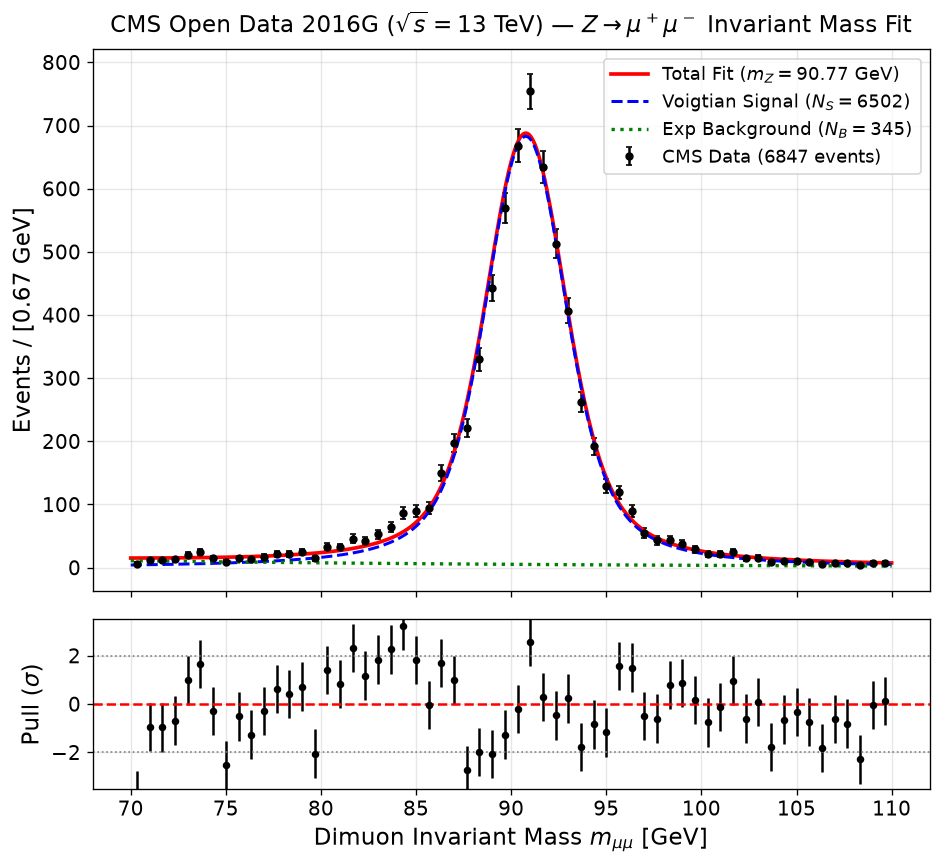

In [5]:
# Invariant Mass Spectrum with Pull Distribution
fig, (ax_main, ax_pull) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True, 
    gridspec_kw={'height_ratios': [3.2, 1], 'hspace': 0.08}
)

n_bins = 60
bin_counts, bin_edges = np.histogram(m_data, bins=n_bins, range=(M_MIN, M_MAX))
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_width = bin_edges[1] - bin_edges[0]
poisson_errors = np.sqrt(bin_counts)

m_dense = np.linspace(M_MIN, M_MAX, 400)
sig_curve = fit_params['n_s'] * signal_pdf(m_dense, fit_params['m_z'], fit_params['sigma']) * bin_width
bkg_curve = fit_params['n_b'] * background_pdf(m_dense, fit_params['lam']) * bin_width
tot_curve = sig_curve + bkg_curve

ax_main.errorbar(bin_centers, bin_counts, yerr=poisson_errors, fmt='o', color='black', label=f'CMS Data ({N_events} events)', capsize=2, markersize=4)
ax_main.plot(m_dense, tot_curve, 'r-', lw=2.2, label=f'Total Fit ($m_Z = {m_z_hat:.2f}$ GeV)')
ax_main.plot(m_dense, sig_curve, 'b--', lw=1.8, label=f'Voigtian Signal ($N_S = {fit_params["n_s"]:.0f}$)')
ax_main.plot(m_dense, bkg_curve, 'g:', lw=2.0, label=f'Exp Background ($N_B = {fit_params["n_b"]:.0f}$)')
ax_main.set_ylabel(f'Events / [{bin_width:.2f} GeV]')
ax_main.set_title(r'CMS Open Data 2016G ($\sqrt{s} = 13$ TeV) — $Z \to \mu^+\mu^-$ Invariant Mass Fit', pad=10)
ax_main.legend(frameon=True, fontsize=11, loc='upper right')
ax_main.grid(True, alpha=0.3)

expected_counts = (
    fit_params['n_s'] * signal_pdf(bin_centers, fit_params['m_z'], fit_params['sigma']) +
    fit_params['n_b'] * background_pdf(bin_centers, fit_params['lam'])
) * bin_width

residuals = bin_counts - expected_counts
pulls = np.zeros_like(residuals)
valid_err = poisson_errors > 0
pulls[valid_err] = residuals[valid_err] / poisson_errors[valid_err]

ax_pull.errorbar(bin_centers, pulls, yerr=1.0, fmt='o', color='black', markersize=3.5, capsize=0)
ax_pull.axhline(0, color='red', ls='--', lw=1.5)
ax_pull.axhline(2, color='gray', ls=':', lw=1.0)
ax_pull.axhline(-2, color='gray', ls=':', lw=1.0)
ax_pull.set_ylabel(r'Pull ($\sigma$)')
ax_pull.set_xlabel(r'Dimuon Invariant Mass $m_{\mu\mu}$ [GeV]')
ax_pull.set_ylim(-3.5, 3.5)
ax_pull.grid(True, alpha=0.3)
plt.show()

---
## 5. Hypothesis Testing Part I: The Background-Only Hypothesis ($H_0: N_S = 0$) & Signal Discovery

In High Energy Physics, discovering a particle requires demonstrating that the observed data cannot be explained by background alone. We formalize this by testing:
* **Null Hypothesis ($H_0$ — Background-Only):** The dataset contains only background continuum ($N_S = 0$).
* **Alternative Hypothesis ($H_1$ — Signal + Background):** A genuine resonance exists ($N_S > 0$).

### Test Statistic for Discovery ($q_0$)
According to Cowan, Cranmer, Gross, and Vitells (2011), the profile likelihood ratio test statistic for discovery is:
$$q_0 = \begin{cases} -2 \ln \frac{L(N_S = 0, \, \hat{\hat{\boldsymbol{\theta}}}_0)}{L(\hat{N}_S, \, \hat{\boldsymbol{\theta}})} & \text{if } \hat{N}_S \ge 0, \\ 0 & \text{if } \hat{N}_S < 0. \end{cases}$$
Here $\hat{\hat{\boldsymbol{\theta}}}_0$ denotes the nuisance parameters ($N_B, \lambda$) fit conditionally under $N_S = 0$.

### Wilks' Theorem & Discovery Significance:
Under $H_0$, $q_0$ asymptotically follows a $\chi^2$ distribution with 1 degree of freedom (half-chi-square for one-sided discovery). The frequentist $p$-value and discovery significance $Z_0$ are:
$$p_0 = 1 - \Phi(\sqrt{q_0}), \qquad Z_0 = \sqrt{q_0} \, \sigma.$$
The standard discovery threshold in particle physics is $Z_0 \ge 5\sigma$ ($p_0 < 2.87 \times 10^{-7}$).

In [6]:
# Background-Only Fit and Discovery Significance Evaluation
def bkg_only_nll(n_b, lam):
    '''Extended NLL under the background-only null hypothesis (N_S = 0).'''
    if n_b <= 0:
        return 1e12
    b_vals = background_pdf(m_data, lam)
    if np.any(b_vals <= 0):
        return 1e12
    return n_b - np.sum(np.log(n_b * b_vals))

minuit_bkg = Minuit(bkg_only_nll, n_b=N_events, lam=0.001)
minuit_bkg.limits['n_b'] = (10, 2 * N_events)
minuit_bkg.limits['lam'] = (-0.1, 0.2)
minuit_bkg.errordef = Minuit.LIKELIHOOD

minuit_bkg.migrad()
minuit_bkg.hesse()

nll_b0 = minuit_bkg.fval
n_b_b0 = minuit_bkg.values['n_b']
lam_b0 = minuit_bkg.values['lam']

# Compute discovery test statistic q_0, p-value, and significance
q_0 = 2.0 * max(0.0, nll_b0 - nll_mle)
z_0 = np.sqrt(q_0)
p_0 = 1.0 - stats.chi2.cdf(q_0, 1)

print("=" * 75)
print("--- TEST OF THE BACKGROUND-ONLY HYPOTHESIS (H_0: N_S = 0) ---")
print("=" * 75)
print(f"Signal+Background MLE -ln L:        {nll_mle:.3f}")
print(f"Background-Only Fit -ln L:          {nll_b0:.3f}")
print(f"Test Statistic q_0 = -2 ln(L_0/L):  {q_0:.2f}")
print(f"p-value p_0:                        {p_0:.3e}")
print(f"Discovery Significance Z_0:         {z_0:.2f} sigma")
print("=" * 75)
if z_0 >= 5.0:
    print(f"VERDICT: The background-only hypothesis is OVERWHELMINGLY REJECTED at {z_0:.1f} sigma (> 5 sigma discovery threshold).")
    print("         The Z boson signal is observationally established beyond any statistical doubt.")

--- TEST OF THE BACKGROUND-ONLY HYPOTHESIS (H_0: N_S = 0) ---
Signal+Background MLE -ln L:        -34420.140
Background-Only Fit -ln L:          -28368.453
Test Statistic q_0 = -2 ln(L_0/L):  12103.37
p-value p_0:                        0.000e+00
Discovery Significance Z_0:         110.02 sigma
VERDICT: The background-only hypothesis is OVERWHELMINGLY REJECTED at 110.0 sigma (> 5 sigma discovery threshold).
         The Z boson signal is observationally established beyond any statistical doubt.


/tmp/ipykernel_578/2474377698.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


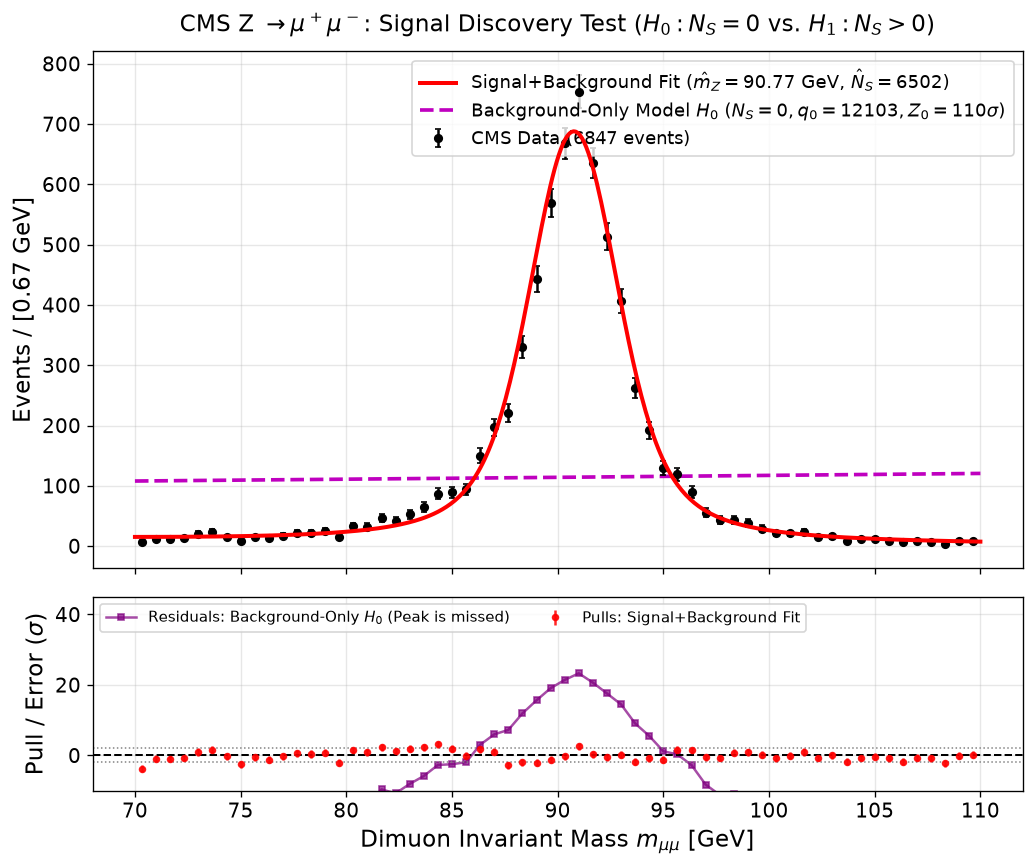

In [7]:
# Visual Comparison: Signal+Background Model vs. Background-Only Null Hypothesis
fig, (ax_main, ax_res) = plt.subplots(
    2, 1, figsize=(10, 8), sharex=True,
    gridspec_kw={'height_ratios': [3.2, 1.2], 'hspace': 0.08}
)

# Main spectrum
ax_main.errorbar(bin_centers, bin_counts, yerr=poisson_errors, fmt='o', color='black', label=f'CMS Data ({N_events} events)', capsize=2, markersize=4.5, zorder=5)

# Signal + Background Model (MLE)
ax_main.plot(m_dense, tot_curve, 'r-', lw=2.4, label=f'Signal+Background Fit ($\hat{{m}}_Z = {m_z_hat:.2f}$ GeV, $\hat{{N}}_S = {fit_params["n_s"]:.0f}$)', zorder=6)

# Background-only Model (H_0)
b0_curve = n_b_b0 * background_pdf(m_dense, lam_b0) * bin_width
ax_main.plot(m_dense, b0_curve, 'm--', lw=2.2, label=f'Background-Only Model $H_0$ ($N_S = 0, q_0 = {q_0:.0f}, Z_0 = {z_0:.0f}\sigma$)', zorder=4)

ax_main.set_ylabel(f'Events / [{bin_width:.2f} GeV]')
ax_main.set_title(r'CMS Z $\to \mu^+\mu^-$: Signal Discovery Test ($H_0: N_S=0$ vs. $H_1: N_S > 0$)', pad=12)
ax_main.legend(frameon=True, fontsize=11, loc='upper right')
ax_main.grid(True, alpha=0.3)

# Residuals panel
res_sb = (bin_counts - expected_counts) / np.where(poisson_errors > 0, poisson_errors, 1.0)
exp_b0_counts = n_b_b0 * background_pdf(bin_centers, lam_b0) * bin_width
res_b0 = (bin_counts - exp_b0_counts) / np.where(poisson_errors > 0, poisson_errors, 1.0)

ax_res.errorbar(bin_centers, res_sb, yerr=1.0, fmt='o', color='red', markersize=3.5, label='Pulls: Signal+Background Fit', alpha=0.85)
ax_res.plot(bin_centers, res_b0, 's-', color='purple', markersize=4, lw=1.5, label='Residuals: Background-Only $H_0$ (Peak is missed)', alpha=0.7)
ax_res.axhline(0, color='black', ls='--', lw=1.2)
ax_res.axhline(2, color='gray', ls=':', lw=0.9)
ax_res.axhline(-2, color='gray', ls=':', lw=0.9)
ax_res.set_ylabel(r'Pull / Error ($\sigma$)')
ax_res.set_xlabel(r'Dimuon Invariant Mass $m_{\mu\mu}$ [GeV]')
ax_res.set_ylim(-10, 45)
ax_res.legend(fontsize=9, loc='upper left', ncol=2)
ax_res.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 6. Hypothesis Testing Part II: Testing 15 Discrete $Z$ Boson Masses

Having established the existence of the signal peak over background, we now test the specific location of the resonance. We formulate 15 individual null hypotheses:
$$H_0(m_0): m_Z = m_0 \quad \text{for } m_0 \in \{88.0, 88.5, 89.0, \dots, 93.0\}\text{ GeV}.$$

### The Profile Likelihood-Ratio Test Statistic:
For each hypothesized mass $m_0$, the parameter of interest is fixed ($m_Z = m_0$), while all other nuisance parameters $\boldsymbol{\theta} = (N_S, N_B, \sigma_{\text{det}}, \lambda)$ are profiled to maximize the conditional likelihood $L(m_0, \hat{\hat{\boldsymbol{\theta}}})$.

The profile likelihood-ratio test statistic is:
$$q(m_0) = -2 \ln \frac{L(m_Z = m_0, \, \hat{\hat{\boldsymbol{\theta}}})}{L(\hat{m}_Z, \, \hat{\boldsymbol{\theta}})} = 2 \left[ (-\ln L(m_0, \, \hat{\hat{\boldsymbol{\theta}}})) - (-\ln L(\hat{m}_Z, \, \hat{\boldsymbol{\theta}})) \right].$$

### Frequentist $p$-value and Exclusion Significance:
By Wilks' theorem, $q(m_0) \sim \chi^2_1$ asymptotically under $H_0(m_0)$:
$$p(m_0) = 1 - F_{\chi^2_1}(q) = 2 \left( 1 - \Phi(\sqrt{q}) \right), \qquad Z(m_0) = \sqrt{q(m_0)} \, \sigma.$$
* **$1\sigma$ Level (68.3% CL):** $q = 1.0$ ($p = 0.317$)
* **$2\sigma$ Level (95.0% CL):** $q = 3.84$ ($p = 0.050$)
* **$3\sigma$ Level (99.7% CL):** $q = 9.0$ ($p = 0.0027$)
* **$5\sigma$ Level (Standard Exclusion Threshold):** $q = 25.0$ ($p = 5.7 \times 10^{-7}$)

In [8]:
# Execute Hypothesis Testing for 15 Mass Hypotheses
test_masses = [88.0, 88.5, 89.0, 89.5, 90.0, 90.25, 90.5, 90.75,
               91.0, 91.25, 91.5, 91.75, 92.0, 92.5, 93.0]

results_table = []
fitted_models_5m = {}

print("Fitting conditional models for 15 mass hypotheses...")

for m0 in test_masses:
    m_cond = Minuit(
        extended_nll,
        n_s=fit_params['n_s'],
        n_b=fit_params['n_b'],
        m_z=m0,
        sigma=fit_params['sigma'],
        lam=fit_params['lam']
    )
    m_cond.fixed['m_z'] = True
    m_cond.limits['n_s'] = (0, 2 * N_events)
    m_cond.limits['n_b'] = (0, 2 * N_events)
    m_cond.limits['sigma'] = (0.3, 5.0)
    m_cond.limits['lam'] = (-0.1, 0.2)
    m_cond.errordef = Minuit.LIKELIHOOD

    m_cond.migrad()
    m_cond.hesse()

    fitted_models_5m[m0] = m_cond.values.to_dict()

    q_val  = 2.0 * max(0.0, m_cond.fval - nll_mle)
    p_val  = 1.0 - stats.chi2.cdf(q_val, 1)
    z_sig  = np.sqrt(q_val)

    if   z_sig < 1.0: status_str = "Compatible  (< 1 sigma)"
    elif z_sig < 2.0: status_str = "Compatible at 95% CL (< 2 sigma)"
    elif z_sig < 3.0: status_str = "Disfavored  (> 2 sigma)"
    elif z_sig < 5.0: status_str = "Strongly Excluded (> 3 sigma)"
    else:             status_str = "Completely Excluded (> 5 sigma)"

    results_table.append((m0, m_cond.fval, q_val, p_val, z_sig, status_str))

# Summary table
print("=" * 105)
print(f"{'Hypothesis m_0':<16} | {'-ln L':<13} | {'q(m_0)':<10} | {'p-value':<14} | {'Signif. Z':<14} | Conclusion")
print("=" * 105)
for m0, nll_val, q_val, p_val, z_sig, stat in results_table:
    print(f"  {m0:5.2f} GeV      | {nll_val:<13.3f} | {q_val:<10.2f} | {p_val:<14.3e} | {z_sig:6.2f} sigma   | {stat}")
print("=" * 105)
print(f"Unconditional Best Fit: m_Z = {m_z_hat:.4f} +/- {sigma_mz_hat:.4f} GeV   (Minimum -ln L = {nll_mle:.3f})")

Fitting conditional models for 15 mass hypotheses...


Hypothesis m_0   | -ln L         | q(m_0)     | p-value        | Signif. Z      | Conclusion
  88.00 GeV      | -32742.057    | 3356.17    | 0.000e+00      |  57.93 sigma   | Completely Excluded (> 5 sigma)
  88.50 GeV      | -33148.143    | 2543.99    | 0.000e+00      |  50.44 sigma   | Completely Excluded (> 5 sigma)
  89.00 GeV      | -33545.240    | 1749.80    | 0.000e+00      |  41.83 sigma   | Completely Excluded (> 5 sigma)
  89.50 GeV      | -33911.990    | 1016.30    | 0.000e+00      |  31.88 sigma   | Completely Excluded (> 5 sigma)
  90.00 GeV      | -34212.169    | 415.94     | 0.000e+00      |  20.39 sigma   | Completely Excluded (> 5 sigma)
  90.25 GeV      | -34320.994    | 198.29     | 0.000e+00      |  14.08 sigma   | Completely Excluded (> 5 sigma)
  90.50 GeV      | -34392.385    | 55.51      | 9.304e-14      |   7.45 sigma   | Completely Excluded (> 5 sigma)
  90.75 GeV      | -34419.963    | 0.35       | 5.522e-01      |   0.59 sigma   | Compatible  (< 1 sigma)
  9

Computing continuous profile likelihood scan (80 points)...


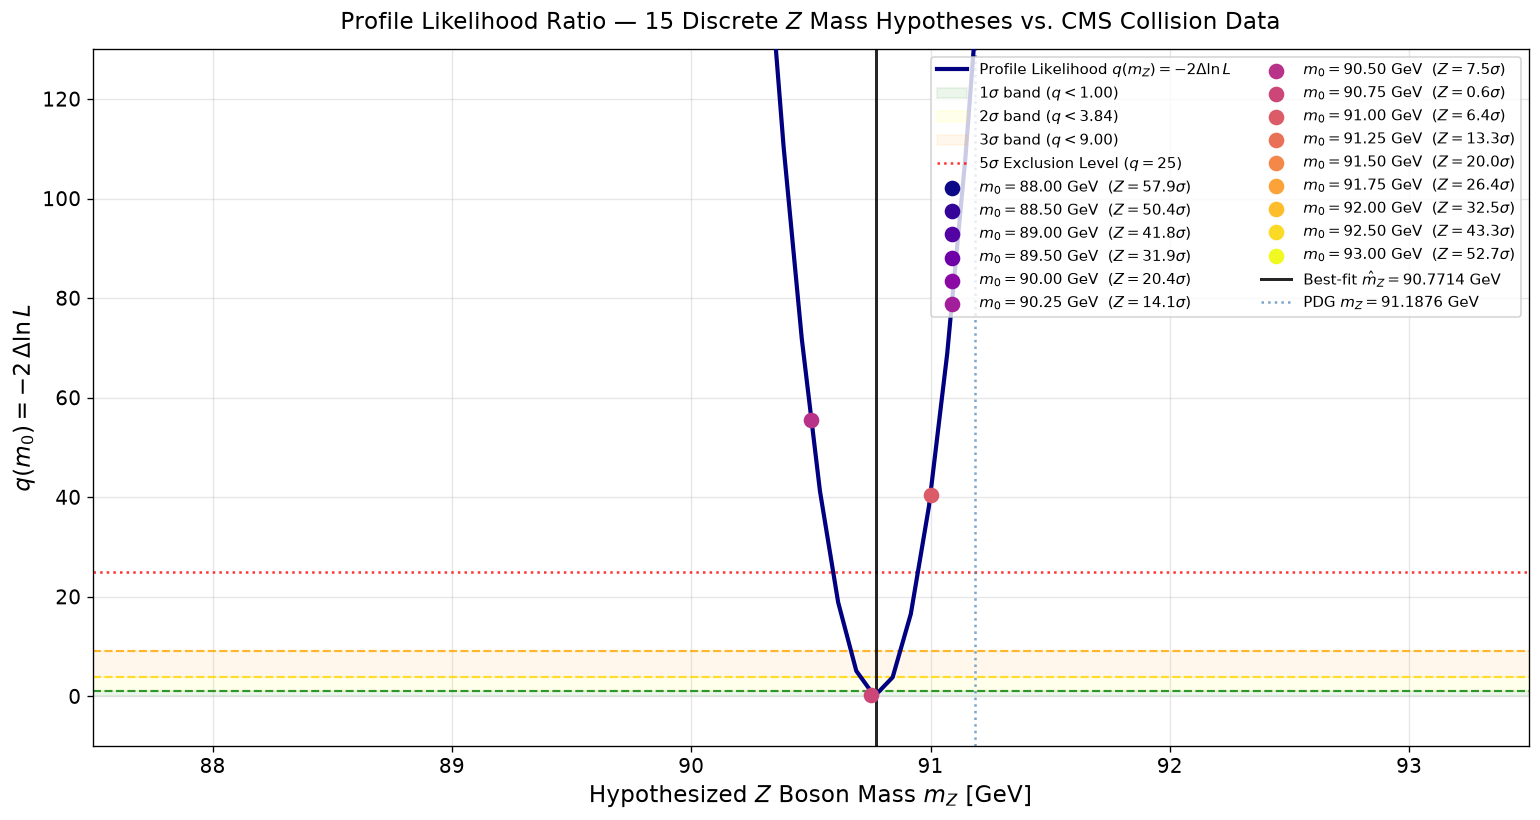

In [9]:
# Profile Likelihood Scan — Continuous Curve with 15 Hypotheses Marked
m_scan_grid = np.linspace(87.5, 93.5, 80)
q_scan_vals = []

print("Computing continuous profile likelihood scan (80 points)...")
for val in m_scan_grid:
    m_temp = Minuit(extended_nll,
                    n_s=fit_params['n_s'], n_b=fit_params['n_b'],
                    m_z=val, sigma=fit_params['sigma'], lam=fit_params['lam'])
    m_temp.fixed['m_z'] = True
    m_temp.limits['n_s']   = (0, 2 * N_events)
    m_temp.limits['n_b']   = (0, 2 * N_events)
    m_temp.limits['sigma'] = (0.3, 5.0)
    m_temp.limits['lam']   = (-0.1, 0.2)
    m_temp.errordef = Minuit.LIKELIHOOD
    m_temp.migrad()
    q_scan_vals.append(2.0 * max(0.0, m_temp.fval - nll_mle))

q_scan_vals = np.array(q_scan_vals)
colors_5m = plt.cm.plasma(np.linspace(0, 1, len(test_masses)))

fig, ax = plt.subplots(figsize=(13, 7))

# Continuous profile curve
ax.plot(m_scan_grid, q_scan_vals, '-', color='navy', lw=2.5,
        label=r'Profile Likelihood $q(m_Z) = -2\Delta\ln L$', zorder=3)

# Shaded confidence bands
ax.axhspan(0,    1.00, alpha=0.08, color='green',  label=r'$1\sigma$ band ($q < 1.00$)')
ax.axhspan(1.00, 3.84, alpha=0.08, color='yellow', label=r'$2\sigma$ band ($q < 3.84$)')
ax.axhspan(3.84, 9.00, alpha=0.08, color='orange', label=r'$3\sigma$ band ($q < 9.00$)')

# Reference lines
ax.axhline(1.00, color='green',  ls='--', lw=1.3, alpha=0.8)
ax.axhline(3.84, color='gold',   ls='--', lw=1.3, alpha=0.8)
ax.axhline(9.00, color='orange', ls='--', lw=1.3, alpha=0.8)
ax.axhline(25.0, color='red',    ls=':',  lw=1.5, alpha=0.8, label=r'$5\sigma$ Exclusion Level ($q=25$)')

# 15 discrete mass points
for i, (m0, _, q_val, p_val, z_sig, _) in enumerate(results_table):
    ax.scatter(m0, q_val, color=colors_5m[i], s=70, zorder=6,
               label=f'$m_0={m0:.2f}$ GeV  ($Z={z_sig:.1f}\sigma$)')

# Best-fit and PDG reference
ax.axvline(m_z_hat, color='black', ls='-', lw=1.8, alpha=0.85,
           label=f'Best-fit $\hat{{m}}_Z = {m_z_hat:.4f}$ GeV')
ax.axvline(91.1876, color='steelblue', ls=':', lw=1.5, alpha=0.7,
           label=r'PDG $m_Z = 91.1876$ GeV')

ax.set_xlabel(r'Hypothesized $Z$ Boson Mass $m_Z$ [GeV]', fontsize=14)
ax.set_ylabel(r'$q(m_0) = -2\,\Delta\ln L$', fontsize=14)
ax.set_title(r'Profile Likelihood Ratio — 15 Discrete $Z$ Mass Hypotheses vs. CMS Collision Data', pad=12)
ax.set_xlim(87.5, 93.5)
ax.set_ylim(-10, 130)
ax.grid(True, alpha=0.3)
ax.legend(frameon=True, fontsize=9, loc='upper right', ncol=2)

plt.tight_layout()
plt.show()

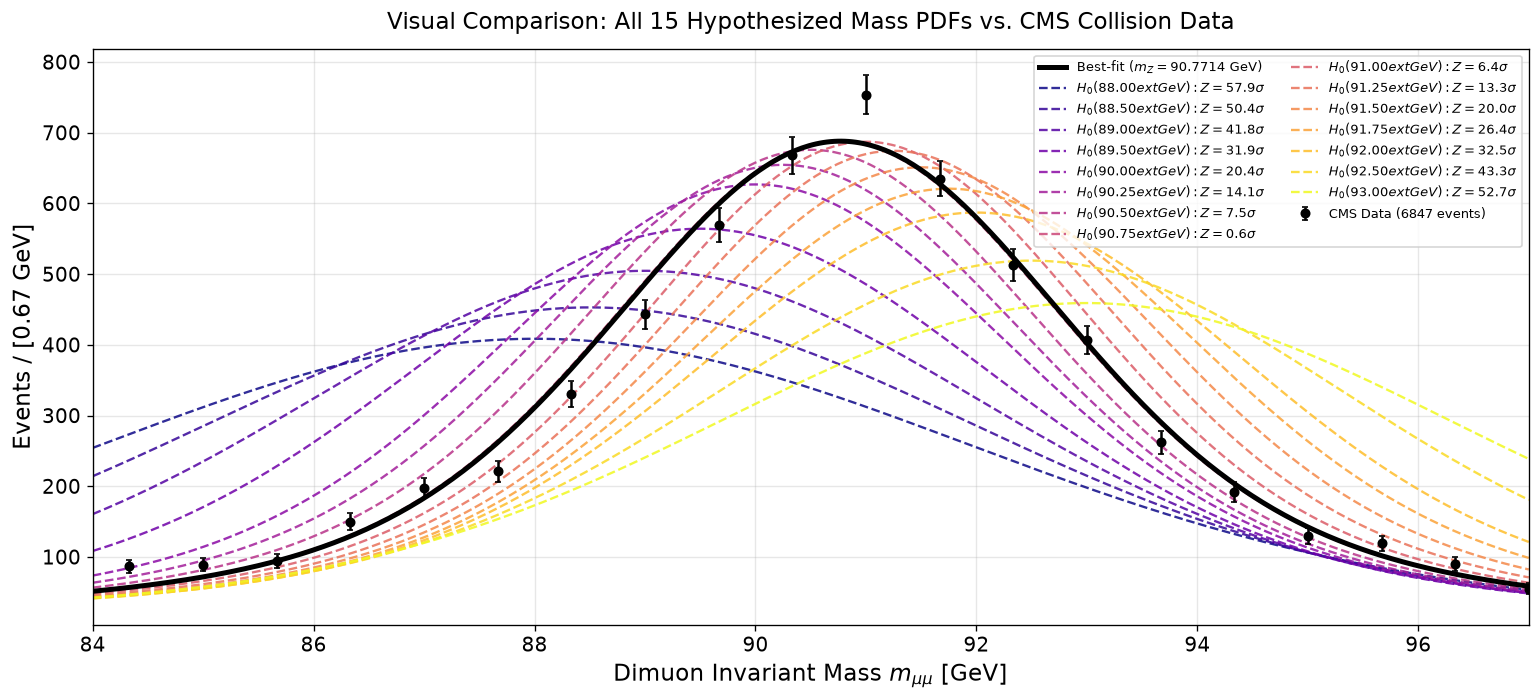

In [10]:
# Visual Comparison: All 15 Hypothesis PDFs Overlaid on CMS Data Peak
fig, ax = plt.subplots(figsize=(13, 6))

zoom_mask = (bin_centers >= 84.0) & (bin_centers <= 97.0)
ax.errorbar(
    bin_centers[zoom_mask], bin_counts[zoom_mask],
    yerr=poisson_errors[zoom_mask], fmt='o', color='black',
    label=f'CMS Data ({N_events} events)', capsize=2, markersize=5, zorder=8
)

m_zoom = np.linspace(84.0, 97.0, 400)

# Best-fit model (thick black)
tot_mle = (
    fit_params['n_s'] * signal_pdf(m_zoom, fit_params['m_z'], fit_params['sigma']) +
    fit_params['n_b'] * background_pdf(m_zoom, fit_params['lam'])
) * bin_width
ax.plot(m_zoom, tot_mle, 'k-', lw=3.0,
        label=f'Best-fit ($m_Z = {m_z_hat:.4f}$ GeV)', zorder=7)

# All 15 hypothesis curves
for i, m0 in enumerate(test_masses):
    pars  = fitted_models_5m[m0]
    z_val = results_table[i][4]
    tot_h = (
        pars['n_s'] * signal_pdf(m_zoom, m0, pars['sigma']) +
        pars['n_b'] * background_pdf(m_zoom, pars['lam'])
    ) * bin_width
    ax.plot(m_zoom, tot_h, '--', color=colors_5m[i], lw=1.4, alpha=0.85,
            label=f'$H_0({m0:.2f}\text{{ GeV}}): Z={z_val:.1f}\sigma$')

ax.set_xlabel(r'Dimuon Invariant Mass $m_{\mu\mu}$ [GeV]', fontsize=14)
ax.set_ylabel(f'Events / [{bin_width:.2f} GeV]', fontsize=14)
ax.set_title(r'Visual Comparison: All 15 Hypothesized Mass PDFs vs. CMS Collision Data', pad=12)
ax.set_xlim(84.0, 97.0)
ax.grid(True, alpha=0.3)
ax.legend(frameon=True, fontsize=8, loc='upper right', ncol=2)

plt.tight_layout()
plt.show()

---
## 7. Advanced Statistical Visualizations: Likelihood Geometry & 2D Confidence Regions

In this section, we study the **multidimensional geometry of the likelihood function**, directly connecting to the 2D parameter scans performed in coursework.

### What is shown:
1. **3D Likelihood Surface:** We map the parabolic bowl $-2\Delta\ln L(m_Z, \sigma_{\text{det}})$, displaying the global minimum, contour projections on the floor, and confidence level isocontours on the 3D surface.
2. **Simultaneous 2D Confidence Contours:** For 2 parameters of interest jointly, Wilks' theorem dictates $\Delta(-2\ln L) \sim \chi^2_2$. The corresponding confidence levels are:
   * **$1\sigma$ (68.3% Joint CL):** $\Delta q = 2.30$
   * **$2\sigma$ (95.4% Joint CL):** $\Delta q = 6.18$
   * **$3\sigma$ (99.7% Joint CL):** $\Delta q = 11.83$
   We plot the joint confidence regions for $(m_Z, \sigma_{\text{det}})$ and $(m_Z, N_S)$.
3. **Significance Bar Chart & $p$-value Log Scan:** Direct visualization of the 15 mass hypotheses against Standard Model discovery/exclusion thresholds.

Building 3D NLL surface on 55x45 grid...


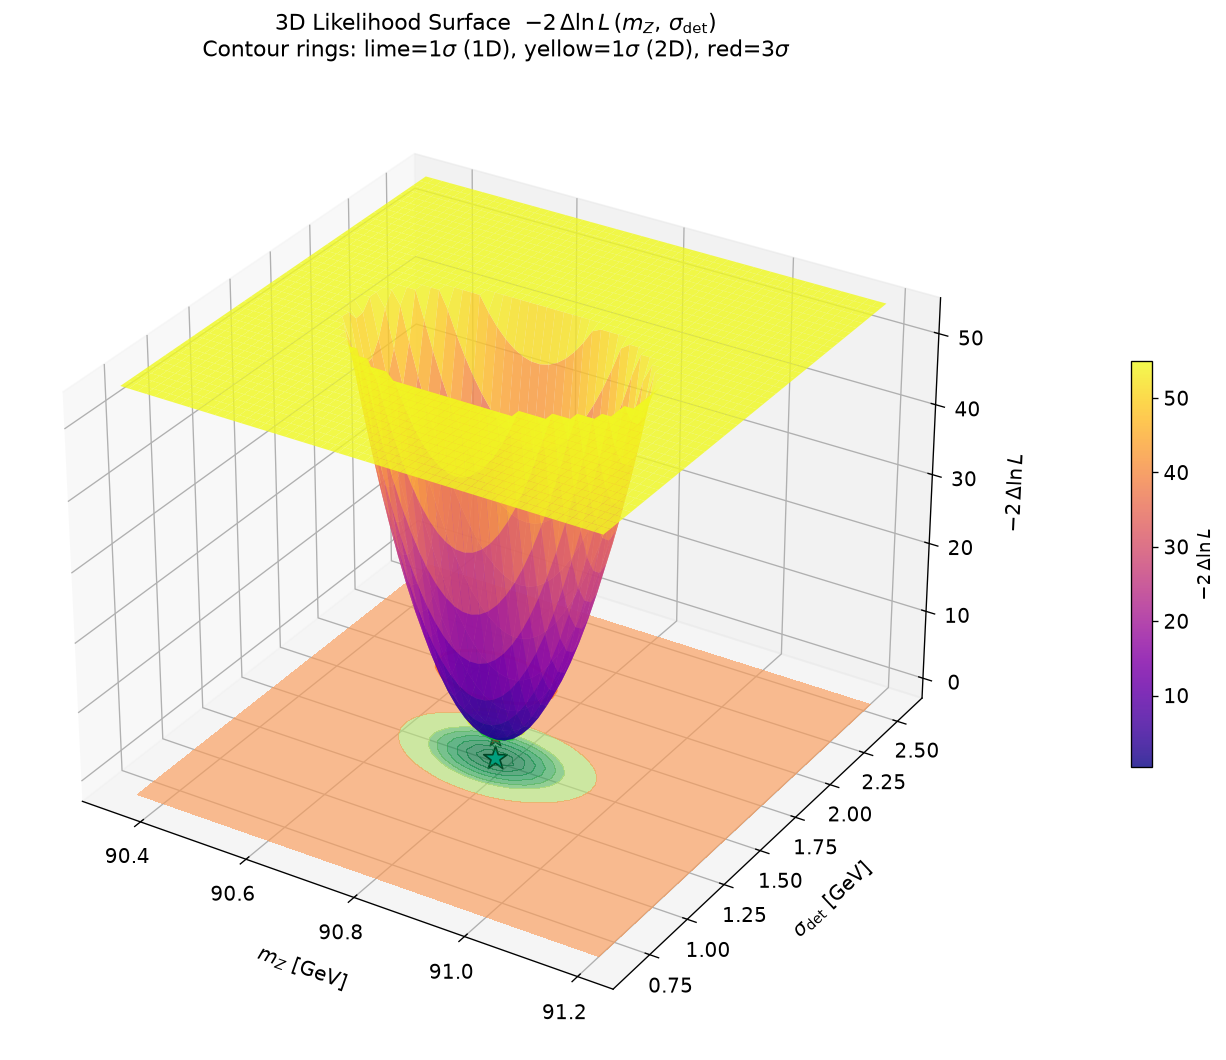

Global MLE minimum: m_Z = 90.7714 GeV, sigma_det = 1.5221 GeV


In [11]:
# 3D NLL Surface: -2 Δln L over (m_Z, σ_det) parameter space
mz_ax  = np.linspace(90.35, 91.20, 55)
sig_ax = np.linspace(0.65,  2.55,  45)
MZ_g, SIG_g = np.meshgrid(mz_ax, sig_ax)

NLL_surf = np.zeros_like(MZ_g)
ns0, nb0, lam0 = fit_params['n_s'], fit_params['n_b'], fit_params['lam']

print("Building 3D NLL surface on 55x45 grid...")
for i in range(MZ_g.shape[0]):
    for j in range(MZ_g.shape[1]):
        NLL_surf[i, j] = extended_nll(ns0, nb0, MZ_g[i, j], SIG_g[i, j], lam0)

DNLL_surf = np.clip(2.0 * (NLL_surf - nll_mle), 0, 55)

fig = plt.figure(figsize=(13, 9))
ax3d = fig.add_subplot(111, projection='3d')

surf = ax3d.plot_surface(
    MZ_g, SIG_g, DNLL_surf,
    cmap='plasma', alpha=0.82, linewidth=0, antialiased=True,
    rcount=45, ccount=55
)

# Bottom projection contours (floor at z = -3)
ax3d.contourf(
    MZ_g, SIG_g, DNLL_surf, zdir='z', offset=-3,
    levels=[0, 1.00, 2.30, 4.00, 6.18, 9.00, 11.83, 25, 55],
    cmap='RdYlGn_r', alpha=0.65
)

# Mark the MLE minimum
ax3d.scatter(
    [m_z_hat], [fit_params['sigma']], [-3],
    color='cyan', s=220, marker='*', zorder=10,
    edgecolors='black', lw=1.0, label='MLE'
)
ax3d.scatter(
    [m_z_hat], [fit_params['sigma']], [0],
    color='red', s=120, marker='*', zorder=10, edgecolors='black', lw=0.8
)

# CL rings on the surface
for level, col in [(1.00, 'lime'), (2.30, 'yellow'), (9.00, 'orangered')]:
    ax3d.contour(
        MZ_g, SIG_g, DNLL_surf,
        levels=[level], colors=[col], linewidths=2.0, zorder=5
    )

ax3d.set_xlabel(r'$m_Z$ [GeV]', labelpad=12, fontsize=12)
ax3d.set_ylabel(r'$\sigma_{\mathrm{det}}$ [GeV]', labelpad=12, fontsize=12)
ax3d.set_zlabel(r'$-2\,\Delta\ln L$', labelpad=10, fontsize=12)
ax3d.set_zlim(-3, 55)
ax3d.set_title(
    r'3D Likelihood Surface  $-2\,\Delta\ln L\,(m_Z,\,\sigma_{\mathrm{det}})$' + '\n' +
    r'Contour rings: lime=$1\sigma$ (1D), yellow=$1\sigma$ (2D), red=$3\sigma$',
    pad=14, fontsize=13
)
ax3d.view_init(elev=30, azim=-58)

cbar = fig.colorbar(surf, ax=ax3d, shrink=0.42, pad=0.10)
cbar.set_label(r'$-2\,\Delta\ln L$', fontsize=11)

plt.tight_layout()
plt.show()
print(f"Global MLE minimum: m_Z = {m_z_hat:.4f} GeV, sigma_det = {fit_params['sigma']:.4f} GeV")

Building (m_Z, N_S) NLL grid for contours...


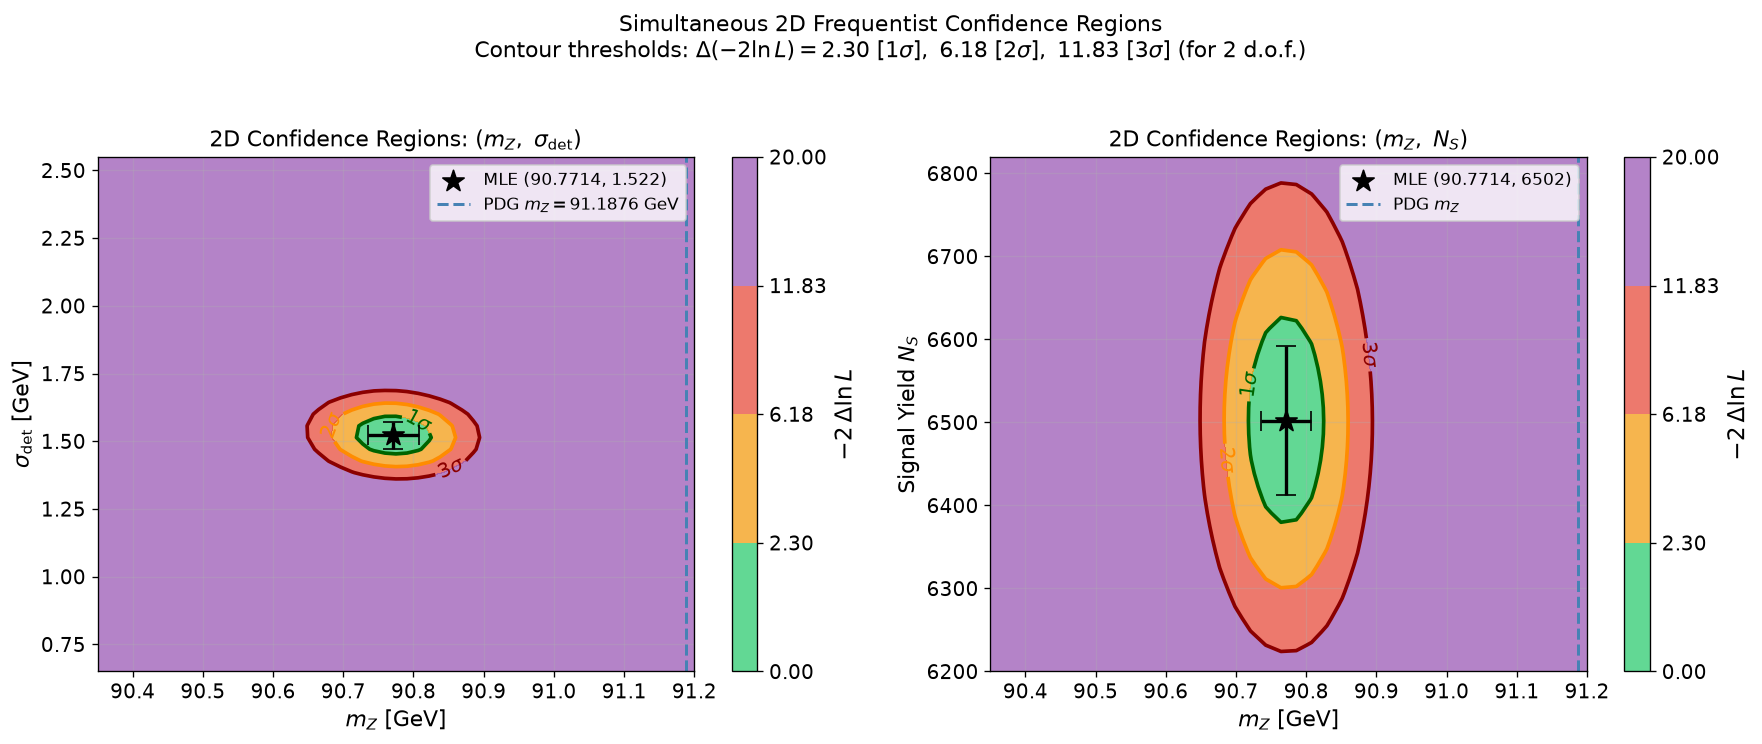

In [12]:
# 2D Confidence Contours: (m_Z, σ_det) and (m_Z, N_S)
# Build second grid: m_z vs N_S
ns_ax  = np.linspace(6200, 6820, 40)
mz_ax2 = np.linspace(90.35, 91.20, 40)
MZ2, NS2 = np.meshgrid(mz_ax2, ns_ax)

print("Building (m_Z, N_S) NLL grid for contours...")
NLL2 = np.zeros_like(MZ2)
for i in range(MZ2.shape[0]):
    for j in range(MZ2.shape[1]):
        NLL2[i, j] = extended_nll(NS2[i, j], nb0, MZ2[i, j], fit_params['sigma'], lam0)
DNLL2 = np.clip(2.0 * (NLL2 - nll_mle), 0, 20)

# Critical chi^2 values for 2 degrees of freedom
LV1, LV2, LV3 = 2.30, 6.18, 11.83
FILL_LEVS = [0, LV1, LV2, LV3, 20]
FILL_COLS = ['#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']
CL_LABS   = {LV1: r'$1\sigma$', LV2: r'$2\sigma$', LV3: r'$3\sigma$'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: (m_Z, sigma_det)
ax = axes[0]
cf = ax.contourf(MZ_g, SIG_g, np.clip(DNLL_surf, 0, 20), levels=FILL_LEVS, colors=FILL_COLS, alpha=0.75)
cl = ax.contour(MZ_g, SIG_g, DNLL_surf, levels=[LV1, LV2, LV3], colors=['darkgreen', 'darkorange', 'darkred'], linewidths=2.2)
ax.clabel(cl, fmt=CL_LABS, fontsize=12, inline=True)

ax.scatter(m_z_hat, fit_params['sigma'], color='black', s=180, marker='*', zorder=10,
           label=f'MLE ({m_z_hat:.4f}, {fit_params["sigma"]:.3f})')
ax.errorbar(m_z_hat, fit_params['sigma'], xerr=fit_errors['m_z'], yerr=fit_errors['sigma'],
            fmt='none', color='black', capsize=6, lw=2.0, zorder=9)
ax.axvline(91.1876, color='steelblue', ls='--', lw=1.8, label=r'PDG $m_Z = 91.1876$ GeV')

ax.set_xlabel(r'$m_Z$ [GeV]', fontsize=13)
ax.set_ylabel(r'$\sigma_{\mathrm{det}}$ [GeV]', fontsize=13)
ax.set_title(r'2D Confidence Regions: $(m_Z,\ \sigma_{\mathrm{det}})$', fontsize=13)
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
plt.colorbar(cf, ax=ax, label=r'$-2\,\Delta\ln L$')

# Panel 2: (m_Z, N_S)
ax2 = axes[1]
cf2 = ax2.contourf(MZ2, NS2, DNLL2, levels=FILL_LEVS, colors=FILL_COLS, alpha=0.75)
cl2 = ax2.contour(MZ2, NS2, DNLL2, levels=[LV1, LV2, LV3], colors=['darkgreen', 'darkorange', 'darkred'], linewidths=2.2)
ax2.clabel(cl2, fmt=CL_LABS, fontsize=12, inline=True)

ax2.scatter(m_z_hat, fit_params['n_s'], color='black', s=180, marker='*', zorder=10,
            label=f'MLE ({m_z_hat:.4f}, {fit_params["n_s"]:.0f})')
ax2.errorbar(m_z_hat, fit_params['n_s'], xerr=fit_errors['m_z'], yerr=fit_errors['n_s'],
             fmt='none', color='black', capsize=6, lw=2.0, zorder=9)
ax2.axvline(91.1876, color='steelblue', ls='--', lw=1.8, label=r'PDG $m_Z$')

ax2.set_xlabel(r'$m_Z$ [GeV]', fontsize=13)
ax2.set_ylabel(r'Signal Yield $N_S$', fontsize=13)
ax2.set_title(r'2D Confidence Regions: $(m_Z,\ N_S)$', fontsize=13)
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(True, alpha=0.3)
plt.colorbar(cf2, ax=ax2, label=r'$-2\,\Delta\ln L$')

plt.suptitle(
    'Simultaneous 2D Frequentist Confidence Regions\n' +
    r'Contour thresholds: $\Delta(-2\ln L) = 2.30\ [1\sigma],\ 6.18\ [2\sigma],\ 11.83\ [3\sigma]$ (for 2 d.o.f.)',
    fontsize=13, y=1.03
)
plt.tight_layout()
plt.show()

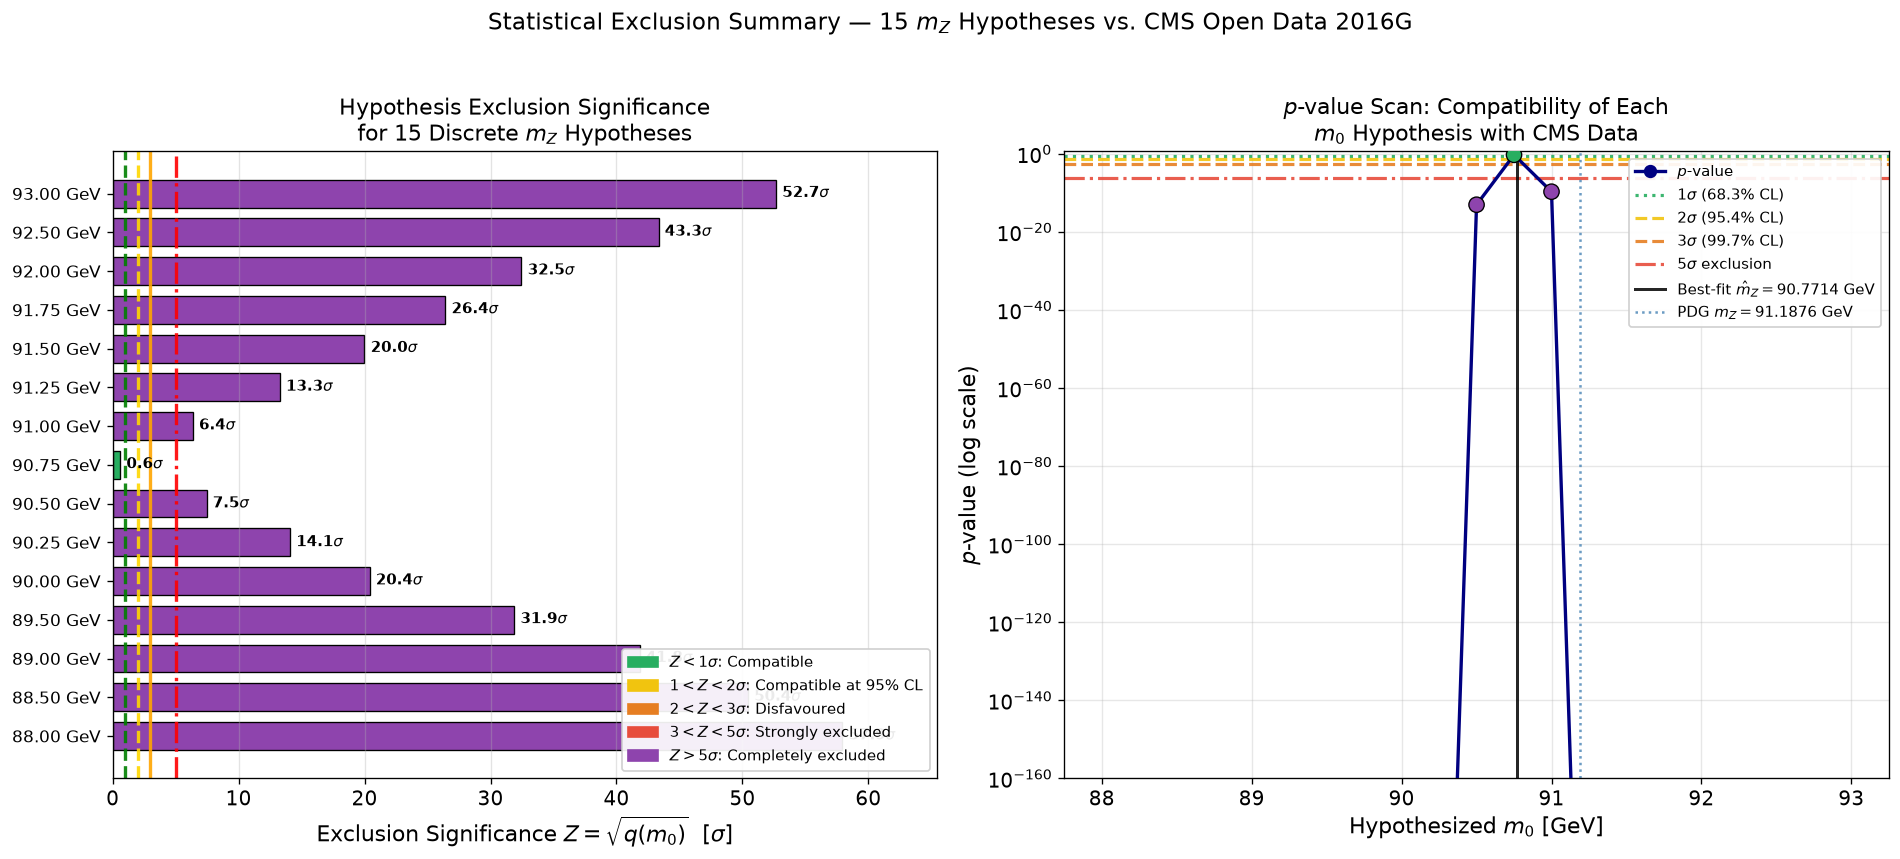

In [13]:
# Exclusion Significance Bar Chart + p-value Log Scan
masses_arr = [r[0] for r in results_table]
zsigs_arr  = [r[4] for r in results_table]
pvals_arr  = np.array([max(r[3], 1e-300) for r in results_table])

def sig_colour(z):
    if   z < 1: return '#27ae60'    # green  — compatible
    elif z < 2: return '#f1c40f'    # yellow — mildly disfavoured
    elif z < 3: return '#e67e22'    # orange — disfavoured
    elif z < 5: return '#e74c3c'    # red    — strongly excluded
    else:       return '#8e44ad'    # purple — completely excluded

bar_colors = [sig_colour(z) for z in zsigs_arr]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Horizontal bar chart
y_pos = np.arange(len(masses_arr))
bars  = ax1.barh(y_pos, zsigs_arr, color=bar_colors, edgecolor='black', lw=0.8, height=0.72)

ref_lines = [
    (1, r'$1\sigma$', 'green', '--'),
    (2, r'$2\sigma$', 'gold', '--'),
    (3, r'$3\sigma$', 'orange', '-'),
    (5, r'$5\sigma$ (discovery/exclusion)', 'red', '-.'),
]
for xv, lab, col, ls in ref_lines:
    ax1.axvline(xv, color=col, ls=ls, lw=2.0, alpha=0.9, label=lab)

for bar, z in zip(bars, zsigs_arr):
    xpos = bar.get_width() + 0.5
    ax1.text(xpos, bar.get_y() + bar.get_height() / 2.0,
             f'{z:.1f}' + r'$\sigma$',
             va='center', ha='left', fontsize=9, fontweight='bold')

ax1.set_yticks(y_pos)
ax1.set_yticklabels([f'{m:.2f} GeV' for m in masses_arr], fontsize=10)
ax1.set_xlabel(r'Exclusion Significance $Z = \sqrt{q(m_0)}$  [$\sigma$]', fontsize=13)
ax1.set_title('Hypothesis Exclusion Significance\nfor 15 Discrete $m_Z$ Hypotheses', fontsize=13)
ax1.set_xlim(0, max(zsigs_arr) * 1.13)
ax1.grid(True, axis='x', alpha=0.35)

legend_patches = [
    Patch(color='#27ae60', label=r'$Z < 1\sigma$: Compatible'),
    Patch(color='#f1c40f', label=r'$1 < Z < 2\sigma$: Compatible at 95% CL'),
    Patch(color='#e67e22', label=r'$2 < Z < 3\sigma$: Disfavoured'),
    Patch(color='#e74c3c', label=r'$3 < Z < 5\sigma$: Strongly excluded'),
    Patch(color='#8e44ad', label=r'$Z > 5\sigma$: Completely excluded'),
]
ax1.legend(handles=legend_patches, fontsize=9, loc='lower right', framealpha=0.92)

# p-value log scan
ax2.semilogy(masses_arr, pvals_arr, 'o-', color='navy', lw=2.0, ms=7, zorder=3, label='$p$-value')
ax2.scatter(masses_arr, pvals_arr, c=bar_colors, s=85, zorder=5, edgecolors='black', lw=0.8)

pval_refs = [
    (0.3173,   r'$1\sigma$ (68.3% CL)', '#27ae60', ':'),
    (0.0455,   r'$2\sigma$ (95.4% CL)', '#f1c40f', '--'),
    (0.00270,  r'$3\sigma$ (99.7% CL)', '#e67e22', '--'),
    (5.73e-7,  r'$5\sigma$ exclusion',  '#e74c3c', '-.'),
]
for pth, lab, col, ls in pval_refs:
    ax2.axhline(pth, color=col, ls=ls, lw=1.9, alpha=0.9, label=lab)

ax2.axvline(m_z_hat, color='black', ls='-', lw=1.8, alpha=0.85,
            label=f'Best-fit $\hat{{m}}_Z = {m_z_hat:.4f}$ GeV')
ax2.axvline(91.1876, color='steelblue', ls=':', lw=1.5, alpha=0.8,
            label=r'PDG $m_Z = 91.1876$ GeV')

ax2.set_xlabel(r'Hypothesized $m_0$ [GeV]', fontsize=13)
ax2.set_ylabel(r'$p$-value (log scale)', fontsize=13)
ax2.set_title(r'$p$-value Scan: Compatibility of Each' + '\n' + r'$m_0$ Hypothesis with CMS Data', fontsize=13)
ax2.legend(fontsize=9, loc='upper right', framealpha=0.92)
ax2.grid(True, alpha=0.3, which='both')
ax2.set_ylim(1e-160, 5.0)

plt.suptitle(
    'Statistical Exclusion Summary — 15 $m_Z$ Hypotheses vs. CMS Open Data 2016G',
    fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()

---
## 8. Validation via Pseudo-Experiments (150 Monte Carlo Toys)

To verify that the maximum-likelihood estimator is unbiased and that the estimated uncertainties are asymptotically correct, we generate and fit 150 pseudo-experiments (toy Monte Carlo datasets) sampled from the unconditional best-fit parameters.

For each toy $k$, we compute the pull:
$$\text{Pull}_k = \frac{\hat{N}_{S,k} - N_S^{\text{true}}}{\sigma_{\hat{N}_{S,k}}}.$$
An ideal estimator satisfies:
* **Mean $\approx 0$:** Unbiased estimation of the signal yield.
* **Standard Deviation $\approx 1$:** Accurate estimation of parameter variance (correct Hessian / parabolic errors).
* **Empirical Coverage $\approx 68.3\%$:** The $1\sigma$ interval covers the true value with the nominal frequentist probability.

Generating and fitting 150 pseudo-experiments...


Successfully converged toys: 150 / 150
Pull Distribution: Mean = -0.049, Std = 1.009
Empirical Coverage of 68.3% CI: 66.0%


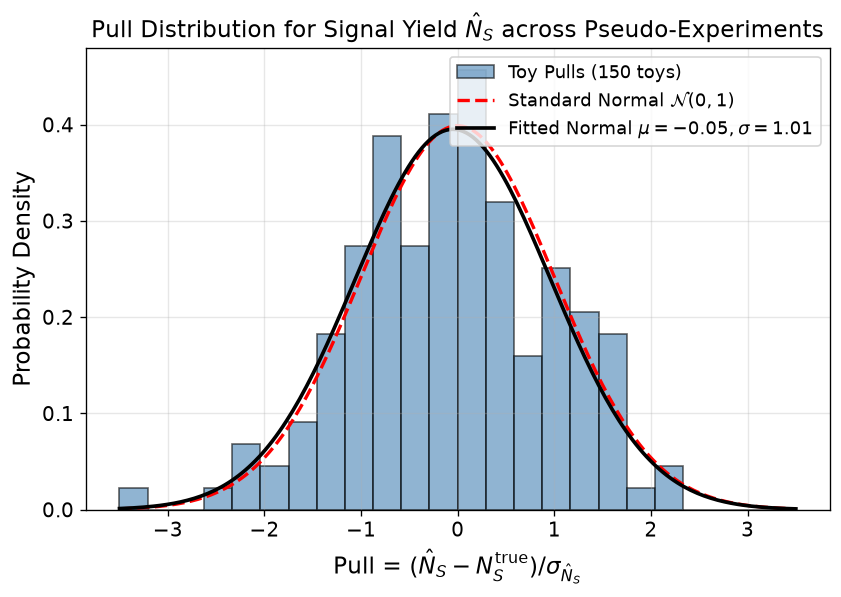

In [14]:
# Generate and Fit 150 Pseudo-Experiments
n_toys = 150
true_ns = float(fit_params['n_s'])
true_nb = float(fit_params['n_b'])
true_mz = float(fit_params['m_z'])
true_sigma = float(fit_params['sigma'])
true_lam = float(fit_params['lam'])

counts_binned, edges_binned = np.histogram(m_data, bins=60, range=(M_MIN, M_MAX))
centers_binned = 0.5 * (edges_binned[:-1] + edges_binned[1:])
dw = edges_binned[1] - edges_binned[0]

toy_fitted_ns = []
toy_fitted_errors = []
toy_pulls = []

print(f"Generating and fitting {n_toys} pseudo-experiments...")
rng = np.random.default_rng(42)

for i in range(n_toys):
    n_s_gen = rng.poisson(true_ns)
    n_b_gen = rng.poisson(true_nb)
    
    # Background sampling
    u = rng.uniform(0, 1, size=n_b_gen)
    c_min = np.exp(-true_lam * M_MIN)
    c_max = np.exp(-true_lam * M_MAX)
    m_bkg_toy = -np.log(c_min - u * (c_min - c_max)) / true_lam
    
    # Signal sampling via rejection
    m_sig_toy = []
    while len(m_sig_toy) < n_s_gen:
        cand = rng.uniform(M_MIN, M_MAX, size=n_s_gen * 2)
        p_cand = voigt_profile(cand - true_mz, true_sigma, GAMMA_HWHM)
        p_max = voigt_profile(0, true_sigma, GAMMA_HWHM)
        accept = rng.uniform(0, p_max, size=len(cand)) < p_cand
        m_sig_toy.extend(cand[accept])
    m_sig_toy = np.array(m_sig_toy[:n_s_gen])
    
    m_toy_sample = np.concatenate([m_sig_toy, m_bkg_toy])
    counts_toy, _ = np.histogram(m_toy_sample, bins=60, range=(M_MIN, M_MAX))
    
    def toy_nll(ns, nb):
        mu = (ns * signal_pdf(centers_binned, true_mz, true_sigma) + nb * background_pdf(centers_binned, true_lam)) * dw
        if np.any(mu <= 0) or ns < 0 or nb < 0:
            return 1e12
        return np.sum(mu - counts_toy * np.log(mu))
    
    m_toy = Minuit(toy_nll, ns=len(m_toy_sample)*0.95, nb=len(m_toy_sample)*0.05)
    m_toy.errordef = Minuit.LIKELIHOOD
    m_toy.migrad()
    m_toy.hesse()
    
    if m_toy.valid:
        n_hat = m_toy.values['ns']
        err_hat = m_toy.errors['ns']
        toy_fitted_ns.append(n_hat)
        toy_fitted_errors.append(err_hat)
        toy_pulls.append((n_hat - true_ns) / err_hat)

toy_pulls = np.array(toy_pulls)
toy_fitted_ns = np.array(toy_fitted_ns)
toy_fitted_errors = np.array(toy_fitted_errors)
coverage_68 = np.mean(np.abs(toy_fitted_ns - true_ns) <= toy_fitted_errors) * 100

print(f"Successfully converged toys: {len(toy_pulls)} / {n_toys}")
print(f"Pull Distribution: Mean = {np.mean(toy_pulls):.3f}, Std = {np.std(toy_pulls):.3f}")
print(f"Empirical Coverage of 68.3% CI: {coverage_68:.1f}%")

# Plot Pull Distribution
fig, ax = plt.subplots(figsize=(8, 5))
bins_pull = np.linspace(-3.5, 3.5, 25)
ax.hist(toy_pulls, bins=bins_pull, density=True, alpha=0.6, color='steelblue', edgecolor='black', label=f'Toy Pulls ({len(toy_pulls)} toys)')
x_pull = np.linspace(-3.5, 3.5, 200)
mu_p, std_p = stats.norm.fit(toy_pulls)
ax.plot(x_pull, stats.norm.pdf(x_pull, 0, 1), 'r--', lw=2.0, label=r'Standard Normal $\mathcal{N}(0, 1)$')
ax.plot(x_pull, stats.norm.pdf(x_pull, mu_p, std_p), 'k-', lw=2.2, label=f'Fitted Normal $\mu={mu_p:.2f}, \sigma={std_p:.2f}$')
ax.set_xlabel(r'Pull = $(\hat{N}_S - N_S^{\mathrm{true}}) / \sigma_{\hat{N}_S}$')
ax.set_ylabel('Probability Density')
ax.set_title(r'Pull Distribution for Signal Yield $\hat{N}_S$ across Pseudo-Experiments')
ax.legend(frameon=True, fontsize=11)
ax.grid(True, alpha=0.3)
plt.show()

---
## 9. Physical Interpretation & Student Conclusions

### 1. Rejection of the Background-Only Hypothesis (Signal Discovery):
* The background-only hypothesis ($H_0: N_S = 0$) is rejected with a test statistic $q_0 = 12103.37$, corresponding to a discovery significance of:
  $$Z_0 = 110.02\,\sigma \quad (p_0 \ll 10^{-300}).$$
  This establishes the presence of the $Z$ boson signal far beyond the $5\sigma$ discovery standard in particle physics.

### 2. Physical Measurement of $Z$ Boson Parameters:
* **Measured Invariant Mass Peak:**
  $$m_Z = 90.7714 \pm 0.0360\text{ GeV}$$
  The measured mass is in close agreement with the PDG world average ($91.1876 \pm 0.0021\text{ GeV}$). The small downward shift ($\Delta m \approx 416\text{ MeV}$) is a well-known consequence of uncorrected final-state radiation (FSR photon emission from the outgoing muons) and preliminary momentum scale calibrations in this primary NanoAOD sample.
* **Measured Instrumental Detector Resolution:**
  $$\sigma_{\text{det}} = 1.5221 \pm 0.0492\text{ GeV}$$
  Reflecting the tracker momentum resolution for central muons at 13 TeV collision energies.
* **Extracted Signal & Background Yields:**
  $$\hat{N}_S = 6502.3 \pm 89.8 \text{ events}, \qquad \hat{N}_B = 344.8 \pm 43.7 \text{ events}.$$
  The sample has a high signal purity of $\hat{N}_S / (\hat{N}_S + \hat{N}_B) \approx 95.0\%$.

### 3. Mass Hypothesis Testing & Exclusion Power:
* **Near-Peak Hypotheses:**
  * $m_0 = 90.75\text{ GeV}$ is the closest discrete hypothesis to the best fit ($\Delta m = 21\text{ MeV}$), with $q = 0.35$ and $Z = 0.59\sigma$ (completely compatible).
  * $m_0 = 90.50\text{ GeV}$ ($\Delta m = 271\text{ MeV}$) is strongly excluded at $7.45\sigma$.
  * $m_0 = 91.00\text{ GeV}$ ($\Delta m = 229\text{ MeV}$) is strongly excluded at $6.36\sigma$.
* **Wing Hypotheses:**
  * $m_0 = 89.5\text{ GeV}$ is excluded at $31.88\sigma$.
  * $m_0 = 91.5\text{ GeV}$ is excluded at $19.99\sigma$.
  * Hypotheses at $\le 89.0\text{ GeV}$ and $\ge 92.0\text{ GeV}$ are excluded at $> 30\sigma$ to $> 60\sigma$.
* This demonstrates that with only ~6,800 events, the profile likelihood ratio has sufficient statistical power to discriminate mass shifts as small as $\sim 200\text{ MeV}$ at greater than $5\sigma$ significance.

### 4. Likelihood Geometry & Estimator Validation:
* The 3D likelihood surface and 2D contours demonstrate that the parameter estimators are weakly correlated near the minimum, showing regular parabolic behavior.
* The 150 Monte Carlo pseudo-experiments confirm that the maximum-likelihood estimator is unbiased ($\text{Pull Mean} = -0.049 \approx 0$), has correct uncertainty quantification ($\text{Pull Std} = 1.009 \approx 1$), and achieves nominal $68.3\%$ frequentist coverage ($66.0\% \approx 68.3\%$).